# Ardoise à tresse, en notebook

Les mêmes vues que la [page web](https://xysticus.github.io/braid-blackboard/), calculées ici par le Python du dépôt :

0. le **diagramme de tresse**, de haut en bas ;
2. l'**action sur le groupe libre et ses lacets** (film par représentation conforme, `python/Conforme.py`) ;
4. l'**action sur le groupe libre et ses rubans** (arcs entre trous fixes et trous voyageurs, `python/Arcs.py`).

Une tresse est une liste d'entiers non nuls : `k` pour σ_k, `-k` pour σ_k⁻¹, lue dans l'ordre (la première lettre
joue la première). Les signes et le sens des demi-tours sont expliqués dans `conventions_de_signe.md`.

Chaque film est une suite d'images calculées une fois, avec un lecteur à curseur et bouton de lecture, comme sur la page
(pas de vidéo, donc rien à encoder). Les films de lacets sont limités à 6 brins et une quarantaine de lettres (comme sur la
page) : au-delà, le calcul est long.
À lancer depuis le répertoire `ipynbks/` (c'est ce que fait JupyterLab en ouvrant ce notebook).

In [1]:
import sys
sys.path.insert(0, '../python')

from io import BytesIO

import cairo
import ipywidgets as widgets
from IPython.display import display

from tresses import calcule_autofn_de_tresse, en_image_pil
from Conforme import dessins_conforme, surface_conforme
from Arcs import FilmArcs

def png(surface):
    """Les octets du PNG d'une surface Cairo."""
    tampon = BytesIO()
    surface.write_to_png(tampon)
    return tampon.getvalue()

def lecteur(images, largeur=500, ms=40):
    """Un film : la suite d'images (octets PNG), avec un bouton de lecture et un curseur (une image toutes les ms
    millisecondes, 25 images par seconde par défaut)."""
    vue = widgets.Image(value=images[0], format='png', width=largeur)
    jeu = widgets.Play(min=0, max=len(images) - 1, step=1, interval=ms, value=0)
    curseur = widgets.IntSlider(min=0, max=len(images) - 1, value=0, readout=False,
                                layout=widgets.Layout(width=f'{largeur - 120}px'))
    widgets.jslink((jeu, 'value'), (curseur, 'value'))          # la lecture avance le curseur
    curseur.observe(lambda changement: setattr(vue, 'value', images[changement['new']]), names='value')
    return widgets.VBox([vue, widgets.HBox([jeu, curseur])])

## La tresse

Modifier le mot ci-dessous, puis relancer les cellules suivantes.

In [2]:
tresse = [1, -2, 1, -2, 3]

## Vue 0 : le diagramme de tresse

Dessiné de haut en bas. Pour σ_i positif, le brin qui va d'en haut à droite vers en bas à gauche passe devant.
Les couleurs sont celles des lacets : le brin de la colonne i au départ est x_i.

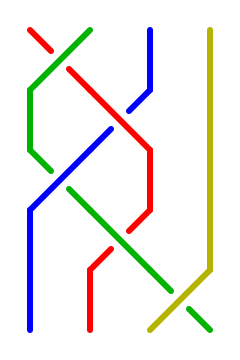

In [3]:
COULEURS = [(1, 0, 0), (0, .7, 0), (0, 0, 1), (.7, .7, 0), (.7, 0, .7), (0, .7, .7)]

def diagramme_de_tresse(tresse, maille=60, largeur_brin=6):
    """Image PIL du diagramme de tresse (première lettre en haut)."""
    n = max(map(abs, tresse), default=1) + 1                 # nombre de brins
    marge = maille // 2
    surface = cairo.ImageSurface(cairo.FORMAT_ARGB32, n * maille, (len(tresse) + 1) * maille)
    ctx = cairo.Context(surface)
    ctx.set_source_rgb(1, 1, 1)
    ctx.paint()
    ctx.set_line_width(largeur_brin)
    ctx.set_line_cap(cairo.LINE_CAP_ROUND)
    couleurs = [COULEURS[i % len(COULEURS)] for i in range(n)]   # couleur du brin dans chaque colonne
    x = lambda colonne: (colonne + 0.5) * maille

    def segment(couleur, c0, y0, c1, y1, de=0.0, a=1.0):
        # le segment de (colonne c0, hauteur y0) à (colonne c1, hauteur y1), de la fraction `de` à la fraction `a`
        ctx.set_source_rgb(*couleur)
        p = lambda t: (x(c0) + t * (x(c1) - x(c0)), y0 + t * (y1 - y0))
        ctx.move_to(*p(de)); ctx.line_to(*p(a)); ctx.stroke()

    for ligne, sigma in enumerate(tresse):
        y0, y1 = marge + ligne * maille, marge + (ligne + 1) * maille
        k = abs(sigma) - 1                                    # le croisement est entre les colonnes k et k + 1
        for c in range(n):
            if c not in (k, k + 1): segment(couleurs[c], c, y0, c, y1)
        trou = 0.3                                            # largeur de l'interruption (fraction du croisement)
        # le brin de gauche va vers la droite, et inversement ; σ_i positif : celui de droite passe devant
        vers_la_droite, vers_la_gauche = (couleurs[k], k, k + 1), (couleurs[k + 1], k + 1, k)
        sous, dessus = (vers_la_droite, vers_la_gauche) if sigma > 0 else (vers_la_gauche, vers_la_droite)
        couleur, depart, arrivee = sous
        segment(couleur, depart, y0, arrivee, y1, 0, 0.5 - trou / 2)       # le brin de dessous est interrompu
        segment(couleur, depart, y0, arrivee, y1, 0.5 + trou / 2, 1)
        segment(dessus[0], dessus[1], y0, dessus[2], y1)
        couleurs[k], couleurs[k + 1] = couleurs[k + 1], couleurs[k]
    return en_image_pil(surface)

display(diagramme_de_tresse(tresse))

## L'action de la tresse sur le groupe libre

`images[i]` est l'image de x_(i+1) : par exemple, pour σ₁, x₁ ↦ x₁x₂x₁⁻¹ et x₂ ↦ x₁ (convention de Birman).

In [4]:
def mot_en_texte(mot):
    return ''.join(f'x{abs(g)}' + ('⁻¹' if g < 0 else '') for g in mot) or '1'

for i, image in enumerate(calcule_autofn_de_tresse(tresse), start=1):
    print(f'x{i}  ↦  {mot_en_texte(image)}')

x1  ↦  x1x3x4x3⁻¹x1⁻¹x3x4⁻¹x3⁻¹x2x3x4x3⁻¹x1x3x4⁻¹x3⁻¹x1⁻¹
x2  ↦  x1x3x4x3⁻¹x1⁻¹
x3  ↦  x3x4⁻¹x3⁻¹x2⁻¹x3x4x3⁻¹x1x3x4⁻¹x3⁻¹x2x3x4x3⁻¹
x4  ↦  x3


## Vue 2 : l'action sur le groupe libre et ses lacets

Chaque lacet x_i part du clou, tourne autour du trou i et revient au clou. Pendant σ_i, les trous i et i+1 tournent
l'un autour de l'autre (demi-tour horaire) et entraînent les lacets. Les lacets sont des arcs de cercle perpendiculaires
aux segments d'une ligne brisée qui se plie : représentation conforme (Schwarz–Christoffel), sans croisement.
Le calcul prend une à deux minutes.

In [5]:
dessins, durees, anomalies = dessins_conforme(tresse, hauteur=800, largeur=800, marge=60, verifie=True)
images = [png(surface_conforme(d, 800, 800, 60, largeur_brin=3)) for d in dessins]
print(len(images), 'images,', len(anomalies), 'anomalie(s)')
lecteur(images)

241 images, 0 anomalie(s)


## Vue 4 : l'action sur le groupe libre et ses rubans

Les lacets sans clou : chaque lacet est le bord d'un ruban mince tendu entre un trou fixe (en bas) et son trou voyageur.
Un seul mouvement continu par lettre, sur une triangulation mobile.

In [6]:
film = FilmArcs(tresse, ecart_fixes=30)
images = [png(film.cadre(rubans=True))]
for sigma in tresse:
    film.lettre(sigma, rendu=lambda f: images.append(png(f.cadre(rubans=True))))
print(len(images), 'images')
lecteur(images)

301 images
